# Week 2 — Preprocessing (TSGF) + Baseline CNN

Two things happen in this notebook:
1. We build the **Trainable Self-Guided Filter (TSGF)** and look at what it does to a real image.
2. We train a **standard CNN** (no spiking, no attention yet) on the preprocessed images, as our
   reference point before we move to the unusual parts of the architecture (spiking neurons, attention,
   Shrike optimization) in later weeks.


In [1]:
import sys
sys.path.append("../src")

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision.transforms as T
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.metrics import confusion_matrix, classification_report

from tsgf import TrainableSelfGuidedFilter
from breakhis_dataset import BreakHisDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


## 1. What the TSGF filter looks like on a real image

`TrainableSelfGuidedFilter` starts with a default smoothing strength (`eps`). Even before any
training, we can look at what it does to a sample image — a smoothed, slightly denoised version
that still preserves the main structures.


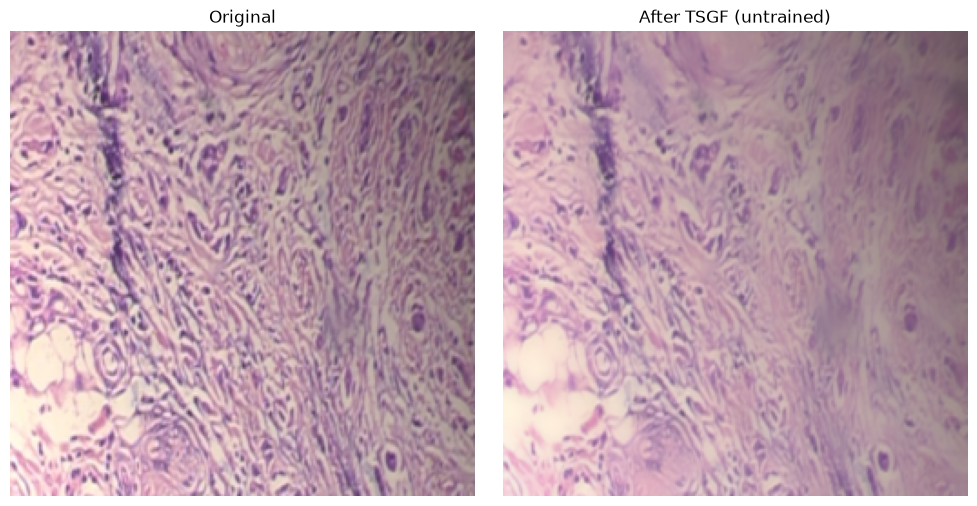

In [2]:
import pandas as pd

df = pd.read_csv("../data/splits/split.csv")
sample_path = "../" + df[df.label == "malignant"].iloc[0]["path"]

to_tensor = T.Compose([T.Resize((256, 256)), T.ToTensor()])
img = Image.open(sample_path).convert("RGB")
x = to_tensor(img).unsqueeze(0)  # add a batch dimension: (1, 3, 256, 256)

tsgf = TrainableSelfGuidedFilter(radius=4)
with torch.no_grad():
    y = tsgf(x)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(x[0].permute(1, 2, 0))
axes[0].set_title("Original")
axes[0].axis("off")
axes[1].imshow(y[0].permute(1, 2, 0))
axes[1].set_title("After TSGF (untrained)")
axes[1].axis("off")
plt.tight_layout()
plt.savefig("../data/splits/tsgf_preview.png", dpi=120)
plt.show()


## 2. Load the dataset with resizing

Full-resolution images (700x460) would be slow to train on with a 4GB GPU, so we resize every
image down to 128x128 pixels before feeding it to the network — standard practice, and small
enough to train quickly while keeping the cell structures visible.


In [3]:
IMG_SIZE = 128
BATCH_SIZE = 32

transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
])

train_ds = BreakHisDataset("../data/splits/split.csv", "train", transform=transform)
val_ds = BreakHisDataset("../data/splits/split.csv", "val", transform=transform)
test_ds = BreakHisDataset("../data/splits/split.csv", "test", transform=transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"train={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}")


train=5279  val=1348  test=1282


## 3. The baseline model: TSGF + a small CNN

Structure: `TSGF filter -> 3 convolutional blocks (conv + batchnorm + relu + downsample) -> fully
connected layers -> 2 output scores (benign, malignant)`.

**What a convolution does:** a small grid of learnable numbers (a "kernel", e.g. 3x3) slides
across the image. At each position it multiplies its numbers against the pixels underneath and
sums them into one output number. Different kernels learn to detect different things — edges,
blobs, textures. Stacking several conv layers lets later layers combine simple patterns (edges)
into complex ones (nucleus shapes, tissue texture).

**What pooling/downsampling does:** shrinks the image (e.g. 128x128 -> 64x64) by keeping only the
strongest signal in each small region, which reduces compute and makes the network care less
about the exact pixel position of a feature.


In [4]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.tsgf = TrainableSelfGuidedFilter(radius=4)

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)

        self.pool = nn.MaxPool2d(2)  # halves height and width each time
        self.gap = nn.AdaptiveAvgPool2d(1)  # collapses each feature map to a single number

        self.fc1 = nn.Linear(64, 32)
        self.fc2 = nn.Linear(32, 2)  # 2 classes: benign, malignant
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = self.tsgf(x)

        x = self.pool(F.relu(self.bn1(self.conv1(x))))   # 128 -> 64
        x = self.pool(F.relu(self.bn2(self.conv2(x))))   # 64 -> 32
        x = self.pool(F.relu(self.bn3(self.conv3(x))))   # 32 -> 16

        x = self.gap(x).flatten(1)  # (batch, 64)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)             # (batch, 2) raw scores, one per class
        return x


model = BaselineCNN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Total trainable parameters: {n_params:,}")


Total trainable parameters: 25,955


## 4. Training loop — with three fixes

Last run had two real problems, diagnosed from the actual results:

1. **Unstable validation loss** (bouncing between 0.27 and 1.47 across epochs) — the learning
   rate (`1e-3`, how big each weight-nudge is) was too large, causing the model to overshoot and
   oscillate instead of settling. Fix: start smaller (`1e-4`), and add a *scheduler* that shrinks
   the learning rate further whenever validation loss stops improving for 2 epochs in a row.
2. **Poor benign recall** (22%) despite decent overall accuracy — malignant images outnumber
   benign ones in training (3402 vs 1877), so the model found it cheap to lean toward guessing
   "malignant." Fix: weight the loss function so a mistake on benign counts proportionally more,
   exactly canceling out the imbalance.

A third addition: **checkpointing**. Instead of just keeping whatever the very last epoch
happens to produce, we now save a copy of the model's weights every time validation loss hits a
new best, and stop early if it goes 6 epochs without improving (mirrors the paper's own Table 3,
which lists "Early Stopping: 10 epochs"). At the end we reload that best-ever snapshot before
evaluating on the test set.


In [ ]:
import copy

# Class weights: inversely proportional to how often each class appears in training data,
# so a mistake on the rarer class (benign) counts for more in the loss.
# Standard "balanced" formula: weight_c = total_samples / (num_classes * count_c)
class_counts = train_ds.df["label"].value_counts()
n_benign = class_counts["benign"]
n_malignant = class_counts["malignant"]
total = n_benign + n_malignant
weight_benign = total / (2 * n_benign)
weight_malignant = total / (2 * n_malignant)
class_weights = torch.tensor([weight_benign, weight_malignant], dtype=torch.float32).to(device)
print(f"Class weights -> benign: {weight_benign:.3f}, malignant: {weight_malignant:.3f}")

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)
criterion = nn.CrossEntropyLoss(weight=class_weights)

MAX_EPOCHS = 25
PATIENCE = 6
best_val_loss = float("inf")
best_state = None
patience_counter = 0
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}


def run_epoch(loader, train: bool):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += images.size(0)
    return total_loss / total, correct / total


for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)
    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    improved = val_loss < best_val_loss
    if improved:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    current_lr = optimizer.param_groups[0]["lr"]
    flag = "  <- best so far" if improved else ""
    print(f"Epoch {epoch}/{MAX_EPOCHS}  "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.3f}  "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.3f}  "
          f"lr={current_lr:.6f}{flag}")

    if patience_counter >= PATIENCE:
        print()
        print(f"Early stopping: no val_loss improvement for {PATIENCE} epochs.")
        break

model.load_state_dict(best_state)
print()
print(f"Restored best checkpoint (val_loss={best_val_loss:.4f})")


## 5. Training curves — checking for overfitting

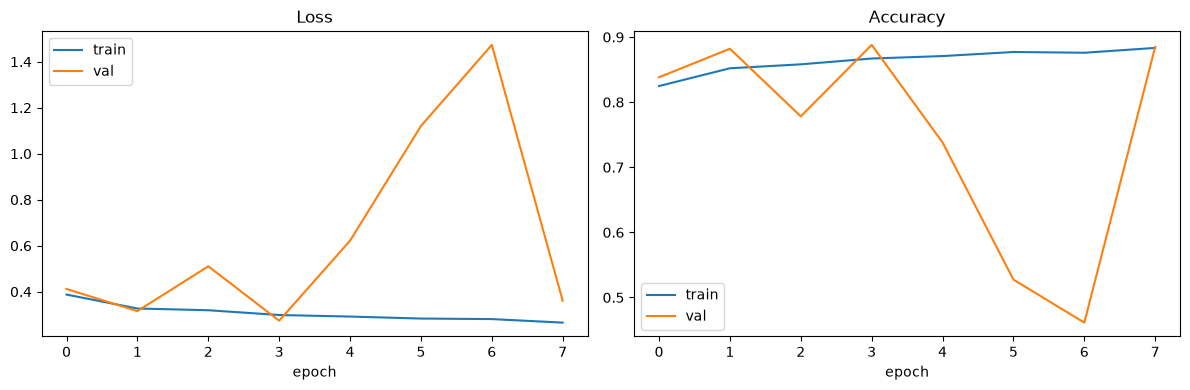

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig("../data/splits/week2_training_curves.png", dpi=120)
plt.show()


If train accuracy keeps climbing while val accuracy flattens or drops, that's **overfitting** —
the model starts memorizing training images instead of learning general patterns. A small
train/val gap is normal and fine.


## 6. Final evaluation on the held-out test set

              precision    recall  f1-score   support

      benign       0.39      0.22      0.28       250
   malignant       0.83      0.92      0.87      1032

    accuracy                           0.78      1282
   macro avg       0.61      0.57      0.58      1282
weighted avg       0.74      0.78      0.76      1282



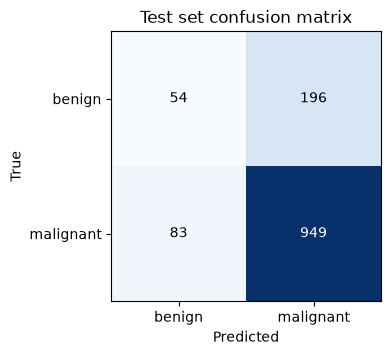

In [7]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=["benign", "malignant"]))

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["benign", "malignant"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["benign", "malignant"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.title("Test set confusion matrix")
plt.tight_layout()
plt.savefig("../data/splits/week2_confusion_matrix.png", dpi=120)
plt.show()


## 7. What the TSGF filter learned

Its smoothing strength (`eps`) was a free parameter during training — let's see what value it
converged to, and preview its effect on the same sample image again.


Learned eps: 0.00654


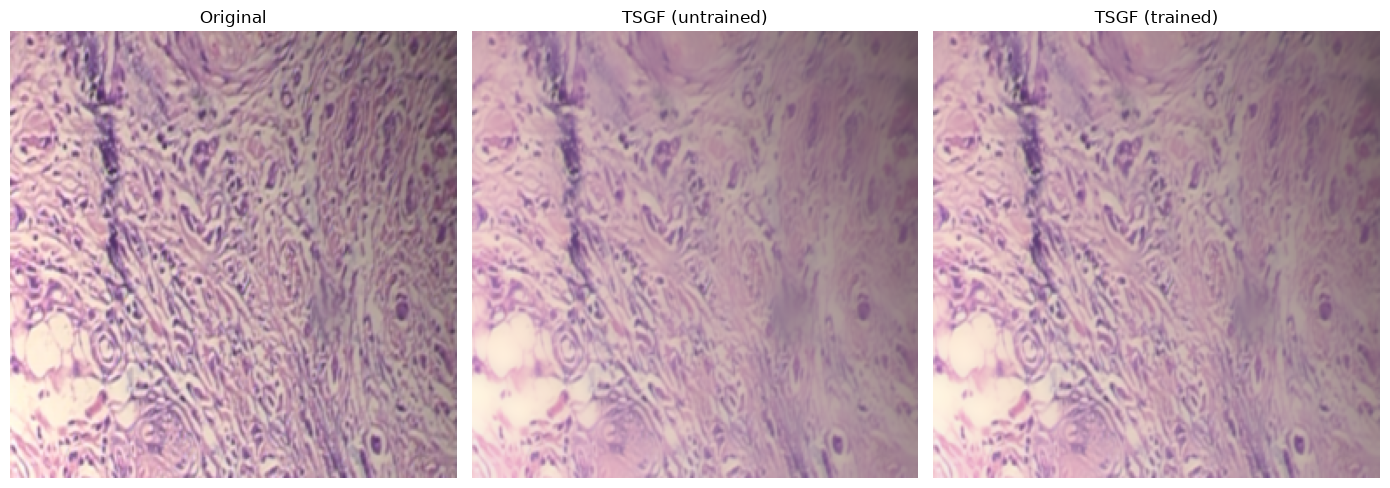

In [8]:
learned_eps = torch.exp(model.tsgf.log_eps).item()
print(f"Learned eps: {learned_eps:.5f}")

with torch.no_grad():
    y_trained = model.tsgf(x.to(device)).cpu()

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(x[0].permute(1, 2, 0)); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(y[0].permute(1, 2, 0)); axes[1].set_title("TSGF (untrained)"); axes[1].axis("off")
axes[2].imshow(y_trained[0].permute(1, 2, 0)); axes[2].set_title("TSGF (trained)"); axes[2].axis("off")
plt.tight_layout()
plt.savefig("../data/splits/tsgf_before_after_training.png", dpi=120)
plt.show()
